In [82]:
import random
import numpy as np
from tqdm import tqdm
import math
import matplotlib.pyplot as plt

In [2]:
class Maze:
    def __init__(self):
        self.maze = [
            "OOOOOOOCG",
            "OOCOOOOCO",
            "SOCOOOOCO",
            "OOCOOOOOO",
            "OOOOOCOOO",
            "OOOOOOOOO",
        ]
        self.starting_state = (2,0)
        self.goal_state = (0, 8)

        self.number_of_steps = 0
        self.current_state = self.starting_state

        self.terminated = 0
        self.truncated = 0

        self.terminal_states = [(1,2), (2, 2), (3, 2), (0, 7), (1, 7), (2, 7), (4, 5), (0,8)]

    def get_action_space(self):
        return ["up", "down", "left", "right"]

    def print_maze(self):
        print(self.maze)

    def change_state(self, action):

        new_state = (0, 0)

        if action == "up":
            if self.current_state[0] == 0:
                return
            new_state = (self.current_state[0] - 1, self.current_state[1])
        elif action == "down":
            if self.current_state[0] == 5:
                return
            new_state = (self.current_state[0] + 1, self.current_state[1])
        elif action == "left":
            if self.current_state[1] == 0:
                return
            new_state = (self.current_state[0], self.current_state[1] - 1)
        elif action == "right":
            if self.current_state[1] == 8:
                return

            new_state = (self.current_state[0], self.current_state[1] + 1)

        if (
            self.maze[new_state[0]][new_state[1]] == "O"
            or self.maze[new_state[0]][new_state[1]] == "S"
        ):
            self.current_state = new_state
        elif self.maze[new_state[0]][new_state[1]] == "G":
            self.current_state = new_state

    def step(self, action):

        if self.terminated or self.truncated:
            observation = self.current_state
            reward = 0
            return observation, reward, self.terminated, self.truncated

        self.number_of_steps += 1

        self.change_state(action)

        observation = self.current_state

        reward = 0
        if self.maze[self.current_state[0]][self.current_state[1]] == "G":
            reward = 1

            self.terminated  = 1
        else:
            reward = 0

        if self.number_of_steps == 1000:
            self.truncated = 1

        return observation, reward, self.terminated, self.truncated

    def reset(self):
        self.number_of_steps = 0
        self.current_state = self.starting_state

        self.terminated = 0
        self.truncated = 0

In [41]:
class ChangingMaze(Maze):
    def __init__(self):

        self.maze = [
            "OOOOOOOOG",
            "OOOOOOOOO",
            "OOOOOOOOO",
            "CCCCCCCCO",
            "OOOOOOOOO",
            "OOOSOOOOO",
        ]

        self.starting_state = (5,3)
        self.goal_state = (0, 8)

        self.number_of_steps = 0
        self.current_state = self.starting_state

        self.terminated = 0
        self.truncated = 0

        self.terminal_states = [
            (3, 0),
            (3, 1),
            (3, 2),
            (3, 3),
            (3, 4),
            (3, 5),
            (3, 6),
            (3, 7),
            (0, 8)
        ]

        self.total_number_of_steps = 0
    def reset(self):
        self.total_number_of_steps += self.number_of_steps

        if self.total_number_of_steps > 1000:
            self.maze = [
                "OOOOOOOOG",
                "OOOOOOOOO",
                "OOOOOOOOO",
                "OCCCCCCCC",
                "OOOOOOOOO",
                "OOOSOOOOO",
            ]

            self.terminal_states = [
                (3, 1),
                (3, 2),
                (3, 3),
                (3, 4),
                (3, 5),
                (3, 6),
                (3, 7),
                (3, 8),
                (0, 8)
            ]

        self.number_of_steps = 0
        self.current_state = self.starting_state

        self.terminated = 0
        self.truncated = 0

In [43]:
maze2 = ChangingMaze()

In [36]:
maze2.terminal_states

[(3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 6), (3, 7), (0, 8)]

In [52]:
maze2.reset()

In [51]:
for i in range(1000):
    maze2.step("left")

In [53]:
maze2.terminal_states

[(3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 6), (3, 7), (3, 8), (0, 8)]

In [128]:
class Dyna_Q:
    def __init__(self, env, n, number_of_episodes = 100):
        self.states_and_actions_taken = {}
        self.env = env
        self.n = n

        self.Q = {}
        self.Model = {}

        self.initialize_Q_and_Model()

        self.number_of_episodes = number_of_episodes

        self.trajectories = []

    def initialize_Q_and_Model(self):

        for row in range(6):
            for col in range(9):
                self.Q[(row, col)] = {"up": 0, "down": 0, "left": 0, "right": 0}
                self.Model[(row, col)] = {"up": (0,0), "down": (0,0), "left": (0,0), "right": (0,0)}

    def get_argmax(self, S):
        state_dict = self.Q[S]

        max_value = max(state_dict.values())
        return [action for action, value in state_dict.items() if value == max_value]

    def get_max(self, S):
        state_dict = self.Q[S]

        action = max(state_dict, key=state_dict.get)
        return self.Q[S][action]

    def get_action(self, epsilon, S):
        action = random.choice(self.env.get_action_space())
        if random.random() > epsilon:
            possible_actions = self.get_argmax(S)
            action = random.choice(possible_actions)

        return action

    def update_state_action_collection(self, S, A):
        if S not in self.states_and_actions_taken:
            self.states_and_actions_taken[S] = []

        if A not in self.states_and_actions_taken[S]:
            self.states_and_actions_taken[S].append(A)

    def get_policy(self):
        policy = {}
        terminal_states = self.env.terminal_states
        for S in self.Q:

            if S in terminal_states:
                policy[S] = "Terminal"
                continue

            A = self.get_argmax(S)[0]

            policy[S] = A
        return policy

    def do_planning_updates(self):
        for _ in range(self.n):

            S = random.choice(list(self.states_and_actions_taken.keys()))
            A = random.choice(self.states_and_actions_taken[S])

            R, S_prime = self.Model[S][A]


            self.Q[S][A] = self.Q[S][A] + 0.1 * (
                R + 0.9999999999999999 * self.get_max(S_prime) - self.Q[S][A]
            )

    def do_one_dyna_Q_iteration(self):
        self.env.reset()

        S = self.env.current_state
        R = 0
        S_prime = self.env.current_state
        terminated = 0
        truncated = 0

        trajectory = []

        while not terminated and not truncated:
            S = S_prime
            trajectory.append(S)
            A = self.get_action(0.8, S)

            self.update_state_action_collection(S, A)

            S_prime, R, terminated, truncated  = self.env.step(A)

            self.Q[S][A] = self.Q[S][A] + 0.1 * (
                R + 0.9999999999999999 * self.get_max(S_prime) - self.Q[S][A]
            )

            self.Model[S][A] = (R, S_prime)

            self.do_planning_updates()

        self.trajectories.append(trajectory)

    def do_dyna_Q(self):
        for i in tqdm(range(self.number_of_episodes)):
            self.do_one_dyna_Q_iteration()

In [5]:
class Dyna_Q_plus(Dyna_Q):

    def __init__(
        self,
        env,
        n,
        κ,
        number_of_episodes=100
    ):
        super().__init__(env, n, number_of_episodes = 100)

        self.κ = κ

    def initialize_Q_and_Model(self):

        for row in range(6):
            for col in range(9):
                self.Q[(row, col)] = {"up": 0, "down": 0, "left": 0, "right": 0}
                self.Model[(row, col)] = {
                    "up": (0, 0, 0),
                    "down": (0, 0, 0),
                    "left": (0, 0, 0),
                    "right": (0, 0, 0),
                }

    def do_planning_updates(self):
        for _ in range(self.n):

            S = random.choice(list(self.states_and_actions_taken.keys()))
            A = random.choice(self.states_and_actions_taken[S])

            R, S_prime, τ = self.Model[S][A]

            self.Q[S][A] = self.Q[S][A] + 0.1 * (
                R + self.κ*math.sqrt(τ) + 0.9999999999999999 * self.get_max(S_prime) - self.Q[S][A]
            )

    def increase_τ(self):
        for row in range(6):
            for col in range(9):

                self.Model[(row, col)]["up"][2] += 1
                self.Model[(row, col)]["down"][2] += 1
                self.Model[(row, col)]["left"][2] += 1
                self.Model[(row, col)]["right"][2] += 1


    def do_one_dyna_Q_iteration(self):
        self.env.reset()

        S = self.env.current_state
        R = 0
        S_prime = self.env.current_state
        terminated = 0
        truncated = 0

        trajectory = []

        while not terminated and not truncated:
            S = S_prime
            trajectory.append(S)
            A = self.get_action(0.2, S)

            self.update_state_action_collection(S, A)

            S_prime, R, terminated, truncated = self.env.step(A)

            self.Q[S][A] = self.Q[S][A] + 0.1 * (
                R + 0.9999999999999999 * self.get_max(S_prime) - self.Q[S][A]
            )


            self.increase_τ()
            self.Model[S][A] = (R, S_prime, 0)

            self.do_planning_updates()

        self.trajectories.append(trajectory)

In [134]:
maze = Maze()

In [135]:
dyna_q = Dyna_Q(maze, 5, 1000)

In [136]:
dyna_q.do_dyna_Q()

100%|██████████| 1000/1000 [00:02<00:00, 396.51it/s]


In [125]:
dyna_q.env.terminal_states

[(3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 6), (3, 7), (3, 8), (0, 8)]

In [132]:
class PlotPolicy():
    def __init__(self, policy):
        self.policy = policy

    def transform_policy(self):
        np_policy = np.array([self.policy[key] for key in self.policy]).reshape(6, 9)
        np_policy = np.where(np_policy == "left", 0, np_policy)
        np_policy = np.where(np_policy == "down", 1, np_policy)
        np_policy = np.where(np_policy == "right", 2, np_policy)
        np_policy = np.where(np_policy == "up", 3, np_policy)
        np_policy = np.where(np_policy == "Terminal", -1, np_policy)


        self.policy = np_policy.astype(float)

    def visualize_policy(self):
        self.transform_policy()

        fig, ax = plt.subplots()
        ax.matshow(self.policy, cmap='Blues')

        for i in range(len(self.policy)):
            for j in range(len(self.policy[0])):
                ax.text(j, i, self.policy[i][j], ha='center', va='center')

        plt.xticks([])
        plt.yticks([])
        plt.show()


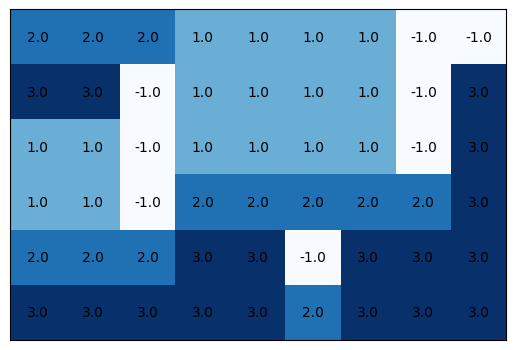

In [137]:
PlotPolicy(dyna_q.get_policy()).visualize_policy()